# Рабочая тетрадь № 3. Самостоятельные задания

Задания разделов 1.3, 2.3 и 3.3. Каждая ячейка с решением запускается отдельно.

## 1. Расстояния между объектами

### Задание 1.3.1

Задайте 4 точки в трехмерном пространстве, рассчитайте между ними расстояния по описанным в примере выше метрикам. Отобразите точки в трехмерном пространстве.

A–B
  Евклид:   5.196152422706632
  Квадрат:  27.0
  Чебышев:  3.0
  Хемминг:  9.0
A–C
  Евклид:   2.23606797749979
  Квадрат:  5.000000000000001
  Чебышев:  2.0
  Хемминг:  3.0
A–D
  Евклид:   4.123105625617661
  Квадрат:  17.0
  Чебышев:  4.0
  Хемминг:  5.0
B–C
  Евклид:   3.7416573867739413
  Квадрат:  14.0
  Чебышев:  3.0
  Хемминг:  6.0
B–D
  Евклид:   3.7416573867739413
  Квадрат:  14.0
  Чебышев:  3.0
  Хемминг:  6.0
C–D
  Евклид:   4.242640687119285
  Квадрат:  17.999999999999996
  Чебышев:  4.0
  Хемминг:  6.0


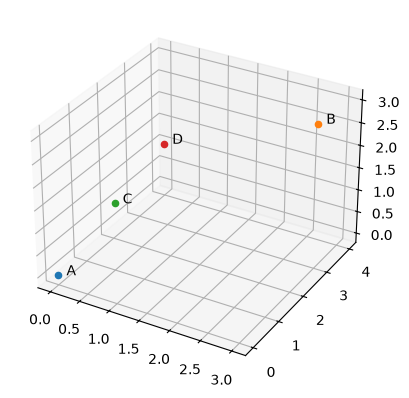

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

points = {
    "A": np.array([0, 0, 0]),
    "B": np.array([3, 3, 3]),
    "C": np.array([1, 0, 2]),
    "D": np.array([0, 4, 1]),
}

names = list(points)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = points[names[i]], points[names[j]]
        print(names[i] + "–" + names[j])
        print("  Евклид:  ", np.linalg.norm(a - b))
        print("  Квадрат: ", np.linalg.norm(a - b) ** 2)
        print("  Чебышев: ", np.linalg.norm(a - b, ord=np.inf))
        print("  Хемминг: ", np.linalg.norm(a - b, ord=1))

fig = plt.figure()
ax = fig.add_subplot(111, projection = '3d')
for name, p in points.items():
    ax.scatter(p[0], p[1], p[2])
    ax.text(p[0], p[1], p[2], "  " + name)
plt.show()

### Задание 1.3.2

Создать 5×5 матрицу со значениями в строках от 0 до 4. Для создания необходимо использовать функцию `arange`.

In [2]:
import numpy as np

Z = np.zeros((5,5))
Z += np.arange(5)
print(Z)

[[0. 1. 2. 3. 4.]
 [0. 1. 2. 3. 4.]
 [0. 1. 2. 3. 4.]
 [0. 1. 2. 3. 4.]
 [0. 1. 2. 3. 4.]]


## 2. Метод k ближайших соседей

### Задание 2.3.1

Для предыдущего примера поэкспериментируйте с параметрами классификатора:

1. Установите другое количество ближайших соседей (k = 1, 5, 10).
2. Установите размер тестовой выборки 15% от всего датасета.
3. Постройте графики и оцените качество моделей, проанализируйте результаты.

Разбиение зафиксировано (`random_state=1`), чтобы три значения k сравнивались на одних и тех же цветках. Оси графиков те же, что в примере 2.2.4: по X ширина лепестка, по Y длина.

k=1: accuracy=1.000, ошибок=0
k=5: accuracy=1.000, ошибок=0
k=10: accuracy=0.957, ошибок=1


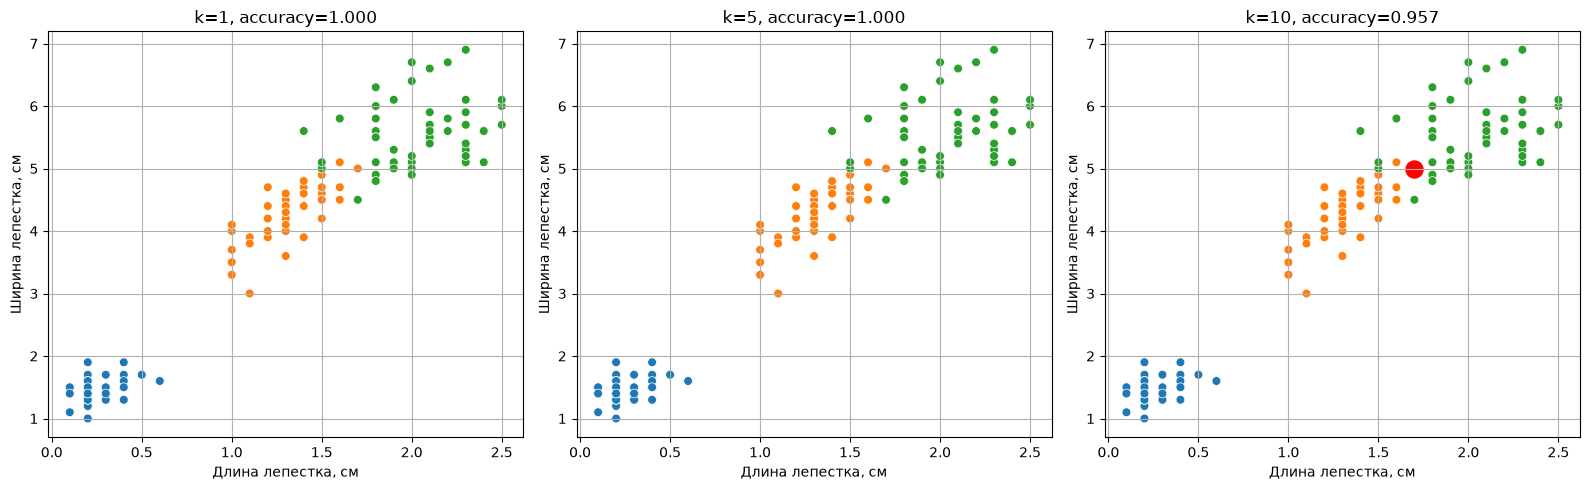

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris = sns.load_dataset('iris')

X_train, X_test, y_train, y_test = train_test_split(
    iris.iloc[:, :-1],
    iris.iloc[:, -1],
    test_size = 0.15,#установили размер тестовой выборки как 15% от всего датасета. 
    random_state=1,
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, k in zip(axes, (1, 5, 10)):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    n_errors = int((np.array(y_test) != y_pred).sum())
    print(f'k={k}: accuracy={acc:.3f}, ошибок={n_errors}')

    sns.scatterplot(x='petal_width', y='petal_length', data=iris, hue='species', s=40, ax=ax, legend=False)
    for i in range(len(y_test)):
        if np.array(y_test)[i] != y_pred[i]:
            ax.scatter(X_test.iloc[i, 3], X_test.iloc[i, 2], color='red', s=150)
    ax.set_title(f'k={k}, accuracy={acc:.3f}')
    ax.set_xlabel('Длина лепестка, см')
    ax.set_ylabel('Ширина лепестка, см')
    ax.grid()

plt.tight_layout()
plt.show()

При k = 1 и k = 5 ошибок на тестовой выборке нет (accuracy 1.000). При k = 10 одна ошибка, accuracy 0.957: versicolor с длиной лепестка 5.0 см и шириной 1.7 см отнесён к virginica. Это цветок на границе двух видов, и большее число соседей перетягивает его в соседний класс. Setosa при всех трёх k отделяется: её лепестки короче и уже. На этом датасете увеличивать k дальше не нужно — граница versicolor и virginica от этого только размывается.

## 3. Категориальные признаки

### Задание 3.3.2

Определите набор признаков человека, по аналогии из РТ 1, — например, цвет глаз — и конвертируйте его в матрицу признаков.

Цвет глаз номинальный, поэтому он не кодируется шкалой 1, 2, 3. `DictVectorizer`, как в примере 3.2.2, разворачивает такие строки в столбцы, а возраст оставляет числом.

In [2]:
from sklearn.feature_extraction import DictVectorizer

people_dict = [
    {"возраст": 21, "пол": "мужской", "цвет глаз": "карий", "образование": "высшее"},
    {"возраст": 19, "пол": "женский", "цвет глаз": "голубой", "образование": "среднее"},
    {"возраст": 22, "пол": "женский", "цвет глаз": "зелёный", "образование": "высшее"},
    {"возраст": 25, "пол": "мужской", "цвет глаз": "карий", "образование": "среднее"},
]

person_vectorizer = DictVectorizer(sparse=False)
person_features = person_vectorizer.fit_transform(people_dict)
print(person_vectorizer.get_feature_names_out())
person_features

['возраст' 'образование=высшее' 'образование=среднее' 'пол=женский'
 'пол=мужской' 'цвет глаз=голубой' 'цвет глаз=зелёный' 'цвет глаз=карий']


array([[21.,  1.,  0.,  0.,  1.,  0.,  0.,  1.],
       [19.,  0.,  1.,  1.,  0.,  1.,  0.,  0.],
       [22.,  1.,  0.,  1.,  0.,  0.,  1.,  0.],
       [25.,  0.,  1.,  0.,  1.,  0.,  0.,  1.]])